# Notebook 1: What is a Backend? Meet the StateBackend

**Class:** Deep Agents Backends
**Source page:** https://docs.langchain.com/oss/python/deepagents/backends

## Where we are in the class

| # | Notebook | Big question it answers |
|---|---|---|
| **1** | **Foundations and StateBackend** | **What is a backend and what does the default one do?** |
| 2 | FilesystemBackend and LocalShellBackend | How do I let the agent touch real files and run commands, safely? |
| 3 | StoreBackend and namespaces | How does an agent remember things across conversations and users? |
| 4 | CompositeBackend routing and ContextHub | How do I mix several storage systems into one filesystem? |
| 5 | Custom backends, permissions, policy hooks | How do I plug in my own storage and enforce rules? |
| 6 | Capstone: choosing the right backend | Which backend for which product? |

## What you will be able to do after this notebook

1. Explain in one sentence what a backend is.
2. Name the filesystem tools a deep agent gets and say which backends add `execute`.
3. Use the default `StateBackend` and see exactly where its files live.
4. Predict when files survive (same thread) and when they vanish (new thread).
5. Show how subagents share the same state filesystem.
6. Watch the agent automatically park a huge tool output in a file and read it back piece by piece.

## 1. The problem a backend solves

An LLM agent has a tiny working memory: its context window. Real tasks produce far more information than fits there:
research notes, drafts, code, logs, big API responses.

Deep Agents solve this by giving the agent a **filesystem**. The agent gets tools that feel exactly like a developer's terminal:

| Tool | What the agent uses it for |
|---|---|
| `ls` | See what files exist in a folder |
| `read_file` | Read a file (with pagination, and images like `.png` `.jpg` come back as real images) |
| `write_file` | Create or overwrite a file |
| `edit_file` | Find and replace inside a file |
| `delete` | Remove a file or folder (hidden automatically if the backend cannot delete) |
| `glob` | Find files by pattern, such as `**/*.md` |
| `grep` | Search inside files for text |
| `execute` | Run shell commands. **Only** with sandbox backends and `LocalShellBackend` |

### The key idea

> The tools are always the same. **Where the bytes actually go** is decided by the **backend**.

Think of it like a laptop and storage drives. The file explorer (the tools) looks the same whether you save to
RAM disk, the SSD, a USB stick, or Google Drive. The backend is the drive you plug in.

The diagram right below shows this flow.

The page lists these built in backends:

| Backend | Where files live | Lifetime |
|---|---|---|
| `StateBackend` (default) | LangGraph agent state | One conversation thread |
| `FilesystemBackend` | Real disk under `root_dir` | Forever (real files) |
| `LocalShellBackend` | Real disk plus shell on your host | Forever, plus commands |
| `StoreBackend` | LangGraph `BaseStore` (memory, Postgres, Redis...) | Across threads |
| `ContextHubBackend` | A LangSmith Context Hub repo | Durable, with commit history |
| Sandbox | Isolated remote machine | Lifetime of the sandbox |
| `CompositeBackend` | A router that sends paths to other backends | Depends on the route |

**Diagram: one set of tools, many possible storage drivers**

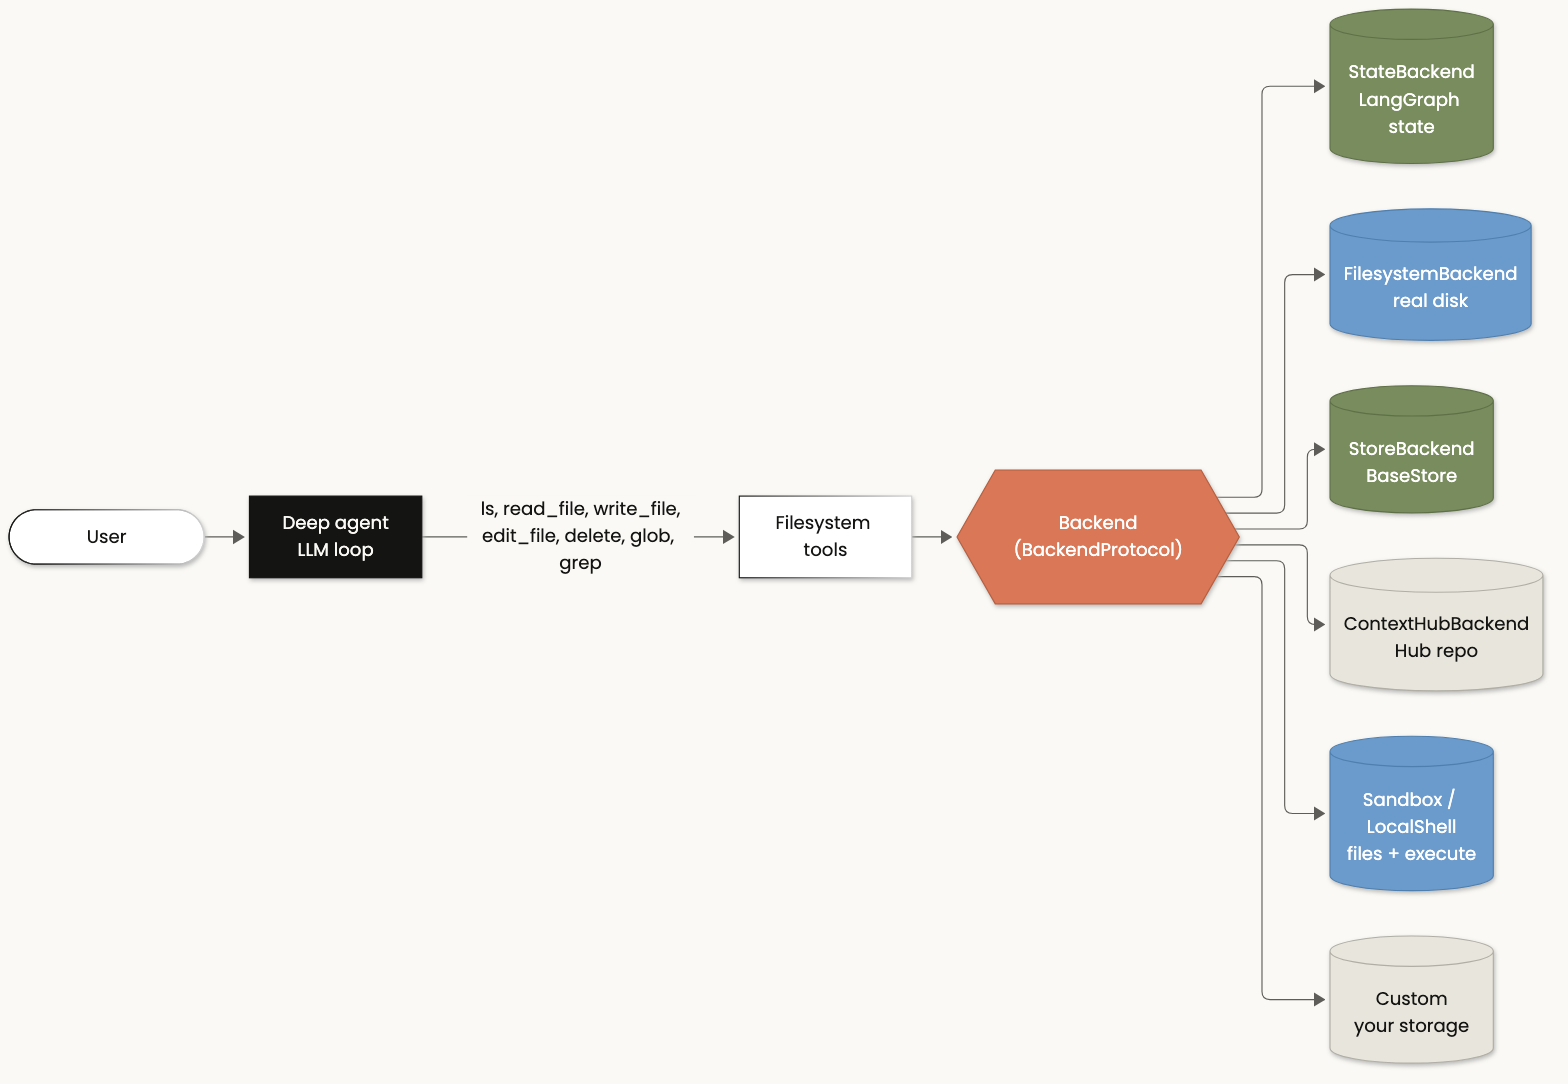

<details><summary>Mermaid source (also saved as diagrams/nb01_architecture.mmd)</summary>

```mermaid
flowchart LR
    U(["User"]) --> A["Deep agent<br/>LLM loop"]
    A -->|"ls, read_file, write_file,<br/>edit_file, delete, glob, grep"| T["Filesystem tools"]
    T --> B{{"Backend<br/>(BackendProtocol)"}}
    B --> S1[("StateBackend<br/>LangGraph state")]
    B --> S2[("FilesystemBackend<br/>real disk")]
    B --> S3[("StoreBackend<br/>BaseStore")]
    B --> S4[("ContextHubBackend<br/>Hub repo")]
    B --> S5[("Sandbox / LocalShell<br/>files + execute")]
    B --> S6[("Custom<br/>your storage")]
    class A dark
    class B orange
    class S1,S3 green
    class S2,S5 blue
    class S4,S6 soft

classDef orange fill:#D97757,stroke:#B65F3F,color:#FFFFFF
classDef green fill:#788C5D,stroke:#5F7048,color:#FFFFFF
classDef blue fill:#6A9BCC,stroke:#4F7FAE,color:#FFFFFF
classDef dark fill:#141413,stroke:#141413,color:#FAF9F5
classDef soft fill:#E8E6DC,stroke:#B0AEA5,color:#141413
classDef bad fill:#F7E3DA,stroke:#D97757,color:#141413

```

</details>

## 2. Setup

We load the OpenAI key from the `.env` file in the project folder. `course_utils.py` also gives us small helpers
(`show_trace`, `show_state_files`) so we can *see* what the agent does instead of guessing.

In [1]:
# Reload the helpers every time, so a kernel that was already running picks up the latest version
import importlib, course_utils
importlib.reload(course_utils)
from course_utils import MODEL, final_text, show_trace, show_state_files, peek
import os

print("Model for this class:", MODEL)
print("OpenAI key loaded:", bool(os.getenv("OPENAI_API_KEY")))

Model for this class: openai:gpt-5.4-mini
OpenAI key loaded: True


## 3. The default backend: `StateBackend`

If you call `create_deep_agent` without a `backend`, you get a `StateBackend`. These two agents are identical:

In [2]:
from deepagents import create_deep_agent
from deepagents.backends import StateBackend

agent_default = create_deep_agent(model=MODEL)

agent_explicit = create_deep_agent(
    model=MODEL,
    backend=StateBackend(),   # exactly what you get by default
)

print("Both agents built. Graph nodes:", list(agent_explicit.get_graph().nodes))

Both agents built. Graph nodes: ['__start__', 'model', 'tools', '_ParentNotifierMiddleware.after_agent', 'PatchToolCallsMiddleware.before_agent', '__end__']


### How it works

* Files are stored **inside the LangGraph agent state**, in a key called `files`.
* State is saved by the **checkpointer** after every step, so files persist across turns **of the same thread**.
* A different thread starts with an empty filesystem. Files are **not shared across threads**.

Let us prove each of these claims instead of trusting them.

**Diagram: files are scoped to a thread, the checkpointer keeps them between turns**

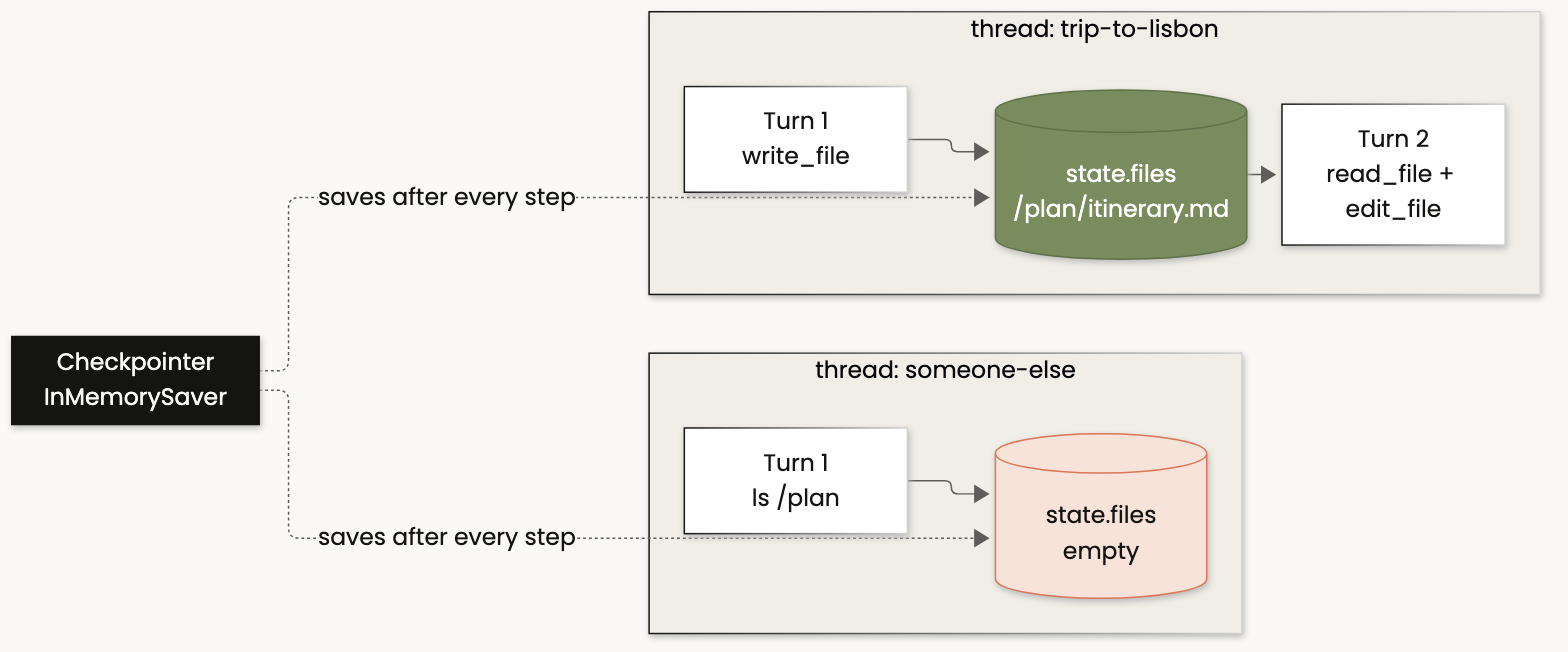

<details><summary>Mermaid source (also saved as diagrams/nb01_threads.mmd)</summary>

```mermaid
flowchart LR
    subgraph T1["thread: trip-to-lisbon"]
        t1a["Turn 1<br/>write_file"] --> st1[("state.files<br/>/plan/itinerary.md")]
        st1 --> t1b["Turn 2<br/>read_file + edit_file"]
    end
    subgraph T2["thread: someone-else"]
        t2a["Turn 1<br/>ls /plan"] --> st2[("state.files<br/>empty")]
    end
    CP[["Checkpointer<br/>InMemorySaver"]] -. "saves after every step" .-> st1
    CP -. "saves after every step" .-> st2
    class st1 green
    class st2 bad
    class CP dark

classDef orange fill:#D97757,stroke:#B65F3F,color:#FFFFFF
classDef green fill:#788C5D,stroke:#5F7048,color:#FFFFFF
classDef blue fill:#6A9BCC,stroke:#4F7FAE,color:#FFFFFF
classDef dark fill:#141413,stroke:#141413,color:#FAF9F5
classDef soft fill:#E8E6DC,stroke:#B0AEA5,color:#141413
classDef bad fill:#F7E3DA,stroke:#D97757,color:#141413

```

</details>

### Scenario A: a scratch pad for a trip planner

A user asks a travel agent to plan a weekend. A good agent writes its plan to a file, so it can refine it later
instead of keeping everything in its head.

In [3]:
from langgraph.checkpoint.memory import InMemorySaver

checkpointer = InMemorySaver()   # saves state per thread_id; use Postgres/SQLite savers in production

planner = create_deep_agent(
    model=MODEL,
    backend=StateBackend(),
    checkpointer=checkpointer,
    system_prompt=(
        "You are a travel planner. Always keep the current itinerary in /plan/itinerary.md. "
        "Keep answers short."
    ),
)

thread_1 = {"configurable": {"thread_id": "trip-to-lisbon"}}

result = planner.invoke(
    {"messages": [{"role": "user", "content": "Plan a 2 day trip to Lisbon for a food lover. Save it to the itinerary file."}]},
    config=thread_1,
)
show_trace(result)

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent LOOKED INSIDE the folder /
         It got back: No files found
Step 2. The agent CREATED (or replaced) the file /plan/itinerary.md
         It got back: Updated file /plan/itinerary.md
THE AGENT'S REPLY TO YOU:
Done - I saved a 2-day Lisbon food-focused itinerary to `/plan/itinerary.md`.

Note: file names in the steps above (starting with /) are the AGENT'S names for files,
not places on your Mac. See 'WHERE DID THE FILES GO?' for where they really are.


### What just happened?

The agent called `write_file`. Nothing touched your hard disk. The file is sitting inside the state dictionary
that LangGraph returned.

> **Why does clicking `/plan/itinerary.md` say "file not found"?**
> That is a **virtual path**: an address inside the agent's backend, not a path on your Mac. Your editor turns it
> into a link to `/plan/itinerary.md` at the root of your disk, where nothing exists. With `StateBackend` the file
> only lives in memory, which is exactly the point of this backend.
>
> To *look* at it, we ask `show_state_files(..., save_as="...")` to write a **snapshot copy** into
> `notebooks/agent_files/`. Those paths are real, so you can click and open them. Editing the snapshot does not
> change the agent's copy.

| Backend | Path the agent sees | Where it really lives | How to view it |
|---|---|---|---|
| `StateBackend` | `/plan/itinerary.md` | `result["files"]` in memory | snapshot via `save_as=` |
| `StoreBackend` | `/profile.md` | store item (namespace, key) | `show_store(..., save_as=)` |
| `FilesystemBackend` | `/REVIEW.md` | `root_dir/REVIEW.md` on disk | `real_path(root_dir, "/REVIEW.md")` |

In [4]:
show_state_files(result, save_as="nb01_trip_planner")
print()
# Show the first file the agent wrote (the model chooses the exact name)
files = result.get("files") or {}
if files:
    first_path = next(iter(files))
    print("Content of", first_path)
    peek(files[first_path]["content"], 600)
else:
    print("The agent did not write a file this time. Rerun the trip planner cell above.")

1 file(s) in agent state (in memory, not on disk):
  /plan/itinerary.md  (1319 chars)
      snapshot to open: /Users/datasense/Desktop/deepagents/notebooks/agent_files/nb01_trip_planner/plan/itinerary.md

Content of /plan/itinerary.md
# 2-Day Lisbon Food Lover Trip

## Day 1: Classic Lisbon Flavors
- **Morning:** Breakfast at a traditional pastelaria with **pastéis de nata** and coffee in Baixa/Chiado.
- **Late morning:** Explore **Time Out Market** for a guided tasting of Portuguese specialties like bacalhau, croquettes, cheese, and local wines.
- **Afternoon:** Walk through Alfama and stop for **petiscos** (Portuguese small plates) at a neighborhood tavern.
- **Evening:** Dinner at a modern Portuguese restaurant focusing on seasonal seafood and regional dishes.
- **After dinner:** Try another pastry stop or a ginjinha liq ...


### Turn 2 on the **same** thread: the file is still there

We do not resend the plan. The agent should find it with `read_file`, then use `edit_file` to change it.

In [5]:
result = planner.invoke(
    {"messages": [{"role": "user", "content": "Swap day 2 dinner for a seafood place. Update the file."}]},
    config=thread_1,
)
show_trace(result)

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent OPENED and read the file /plan/itinerary.md
         It got back: (lines 1 to 20 of 20) # 2-Day Lisbon Food Lover Trip / ## Day 1: Classic Lisbon Flavors / - **Morning:** Breakfast at a traditional pastelaria with **pastéis de ...
Step 2. The agent CHANGED part of the file /plan/itinerary.md
         It got back: Successfully replaced 1 instance(s) of the string in '/plan/itinerary.md'
THE AGENT'S REPLY TO YOU:
Updated the file with a seafood dinner for day 2.

Note: file names in the steps above (starting with /) are the AGENT'S names for files,
not places on your Mac. See 'WHERE DID THE FILES GO?' for where they really are.


### A **new** thread: empty filesystem

Same agent, same checkpointer, different `thread_id`. This is a new conversation, so it gets a fresh filesystem.

In [6]:
thread_2 = {"configurable": {"thread_id": "someone-else"}}

result = planner.invoke(
    {"messages": [{"role": "user", "content": "List the files in /plan/ and tell me what you see."}]},
    config=thread_2,
)
show_trace(result)
show_state_files(result, save_as="nb01_new_thread")

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent LOOKED INSIDE the folder /plan
         It got back: No files found
THE AGENT'S REPLY TO YOU:
I checked `/plan/` and it’s empty - no files found.

Note: file names in the steps above (starting with /) are the AGENT'S names for files,
not places on your Mac. See 'WHERE DID THE FILES GO?' for where they really are.
No files in agent state.


### Self check

Before running the next cell, predict: *if we ask thread 1 again, will the itinerary still be there?*

Answer: yes. The checkpointer stored thread 1's state, including its `files`. Thread isolation does not delete anything,
it only scopes it.

In [7]:
state = planner.get_state(thread_1)
print("Thread 1 still has:", list(state.values["files"].keys()))

Thread 1 still has: ['/plan/itinerary.md']


## 4. Subagents share the same state filesystem

The page warns: *this backend is shared between the supervisor agent and subagents, and any files a subagent writes
remain in the LangGraph agent state after that subagent finishes.*

This is a feature. A research subagent can write long notes to a file, return a short summary, and the supervisor
(or another subagent) can read the full notes later without bloating anyone's context.

### Scenario B: a market research team

* `researcher` subagent: writes detailed notes to `/research/notes.md`.
* Supervisor: reads those notes and writes a short executive brief to `/report/brief.md`.

**Diagram: a subagent hands off its work through a shared file**

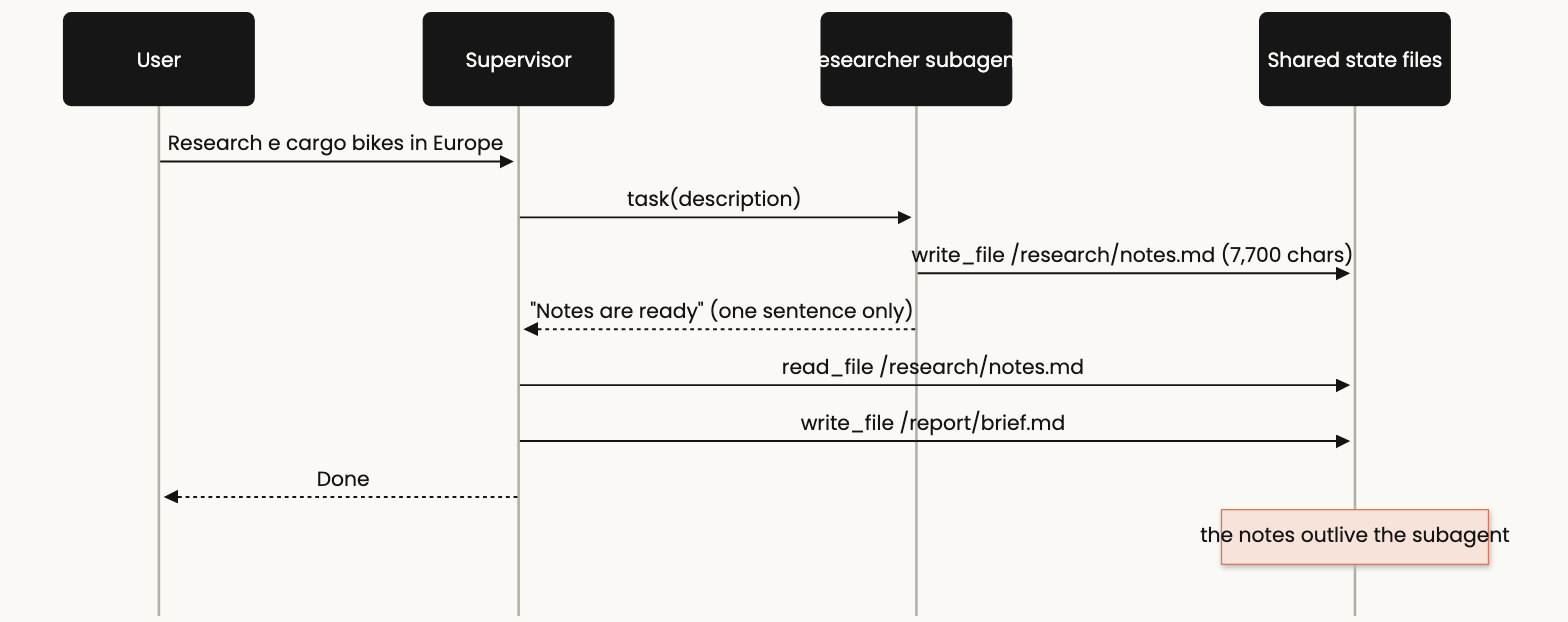

<details><summary>Mermaid source (also saved as diagrams/nb01_subagents.mmd)</summary>

```mermaid
sequenceDiagram
    participant U as User
    participant S as Supervisor
    participant R as researcher subagent
    participant F as Shared state files
    U->>S: Research e cargo bikes in Europe
    S->>R: task(description)
    R->>F: write_file /research/notes.md (7,700 chars)
    R-->>S: "Notes are ready" (one sentence only)
    S->>F: read_file /research/notes.md
    S->>F: write_file /report/brief.md
    S-->>U: Done
    Note over F: the notes outlive the subagent
```

</details>

In [8]:
research_team = create_deep_agent(
    model=MODEL,
    backend=StateBackend(),
    checkpointer=InMemorySaver(),
    subagents=[
        {
            "name": "researcher",
            "description": "Writes detailed research notes on a topic into /research/notes.md",
            "system_prompt": (
                "You are a researcher. Write 8 to 10 detailed bullet notes from your own knowledge "
                "into /research/notes.md, then reply with one sentence saying the file is ready."
            ),
        }
    ],
    system_prompt=(
        "You are a supervisor. Delegate research to the researcher subagent. "
        "Then read /research/notes.md yourself and write a 5 line brief to /report/brief.md."
    ),
)

result = research_team.invoke(
    {"messages": [{"role": "user", "content": "Research the market for electric cargo bikes in Europe."}]},
    config={"configurable": {"thread_id": "market-1"}},
)
show_trace(result)
print()
show_state_files(result, save_as="nb01_research_team")

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent ASKED a helper agent to Research the market for electric cargo bikes in Europe. Focus on market size, growth drivers, key co ...
         It got back: I wrote detailed research notes on the European electric cargo bike market to `/research/notes.md`, covering market size, growth drivers, key countries, custome ...
Step 2. The agent OPENED and read the file /research/notes.md
         It got back: (lines 1 to 69 of 69) # Electric Cargo Bikes in Europe - Research Notes / ## 1) Market size and growth / - The European electric cargo bike market is still nich ...
Step 3. The agent CREATED (or replaced) the file /report/brief.md
         It got back: Updated file /report/brief.md
THE AGENT'S REPLY TO YOU:
Done - I wrote the 5-line brief to `/report/brief.md`.

Note: file names in the steps above (starting with /) are the AGENT'S names for files,
not places on your Mac. See 'WHERE DID THE FILES GO?' for where they really are.

2 file(s) in ag

### What just happened?

1. The supervisor called the `task` tool to start the `researcher` subagent.
2. The subagent wrote `/research/notes.md` into the **shared** state.
3. The subagent finished and returned only a one line message (small context for the supervisor).
4. The supervisor then used `read_file` on the notes. The file outlived the subagent.

**Teaching point:** files are the cheapest way for agents to hand off large work products to each other.

## 5. Automatic eviction of large tool outputs

The second "best for" on the page: *automatic eviction of large tool outputs which the agent can then read back
piece by piece.*

When a tool returns a huge result (default limit about 20,000 tokens), the filesystem middleware:

1. Writes the full result to `/large_tool_results/<tool_call_id>` in the backend.
2. Gives the model only a short preview plus the file path.
3. The model then uses `read_file` with offset/limit, or `grep`, to look at just what it needs.

### Scenario C: a log analysis agent

A tool returns a massive server log (thousands of lines). One line hides the real error.

**Diagram: a huge tool result is parked in a file and searched instead of read**

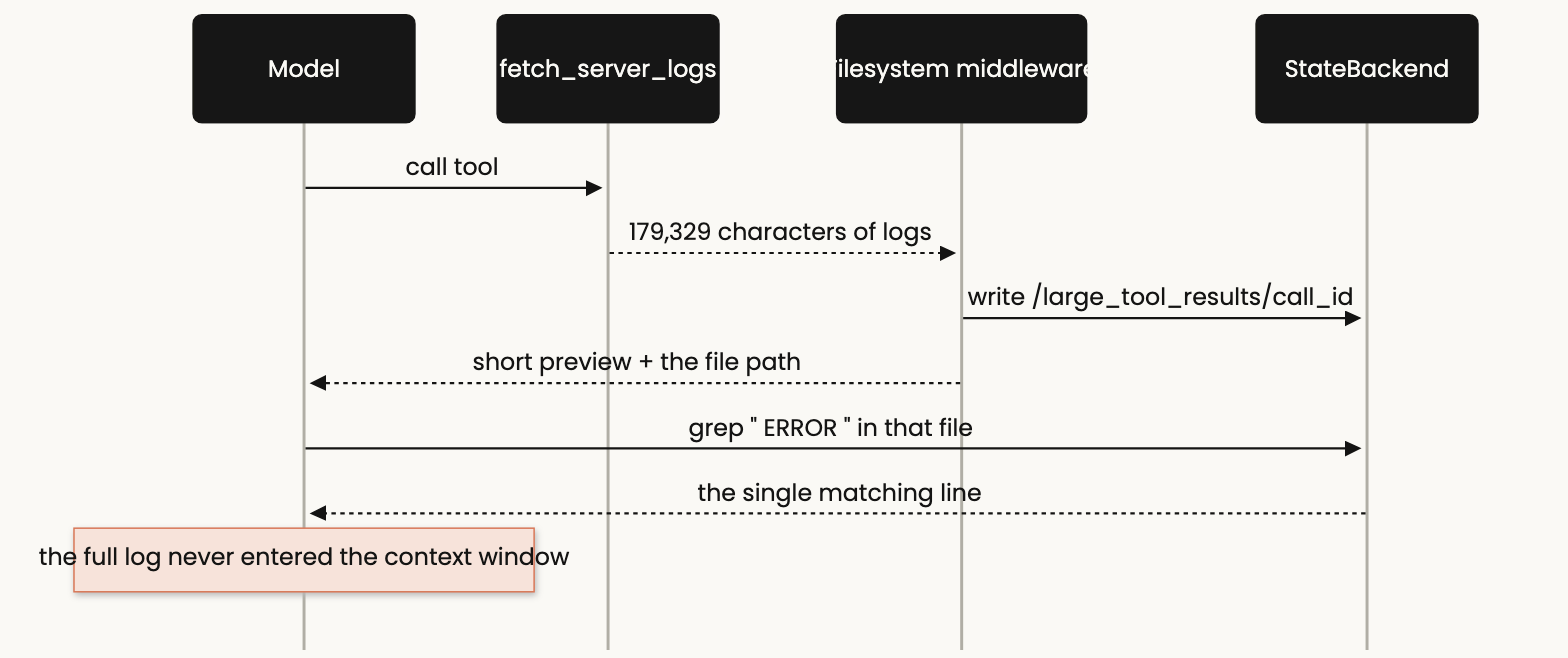

<details><summary>Mermaid source (also saved as diagrams/nb01_eviction.mmd)</summary>

```mermaid
sequenceDiagram
    participant M as Model
    participant T as fetch_server_logs
    participant MW as Filesystem middleware
    participant F as StateBackend
    M->>T: call tool
    T-->>MW: 179,329 characters of logs
    MW->>F: write /large_tool_results/call_id
    MW-->>M: short preview + the file path
    M->>F: grep " ERROR " in that file
    F-->>M: the single matching line
    Note over M: the full log never entered the context window
```

</details>

In [9]:
import random
from langchain_core.tools import tool

@tool
def fetch_server_logs(service: str) -> str:
    """Fetch the full raw log file for a service."""
    random.seed(7)
    lines = []
    for i in range(2500):
        level = random.choice(["INFO", "INFO", "INFO", "DEBUG"])
        lines.append(f"2026-10-30T10:{i // 60:02d}:{i % 60:02d}Z {level} {service} request handled id={i} latency={random.randint(5, 90)}ms")
    lines[1873] = f"2026-10-30T10:31:13Z ERROR {service} PaymentGatewayTimeout after 30000ms id=1873 card_region=EU"
    return "\n".join(lines)

print("Log size in characters:", len(fetch_server_logs.invoke({"service": "checkout"})))

Log size in characters: 179329


In [10]:
log_agent = create_deep_agent(
    model=MODEL,
    tools=[fetch_server_logs],
    backend=StateBackend(),
    system_prompt="You are an SRE assistant. Find root causes in logs. Be concise.",
)

result = log_agent.invoke(
    {"messages": [{"role": "user", "content": "Fetch the checkout service logs and tell me the single ERROR line and its id."}]}
)
show_trace(result, limit=220)
print()
show_state_files(result, save_as="nb01_log_agent")

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent USED its tool 'fetch_server_logs'
         The answer was too big to read at once, so it was saved to the file /large_tool_results/call_W5bntz7SrHR56i6LkBMwnASL
Step 2. The agent SEARCHED inside files for the text  ERROR
         It got back: /large_tool_results/call_W5bntz7SrHR56i6LkBMwnASL: / 1874: 2026-10-30T10:31:13Z ERROR checkout PaymentGatewayTimeout after 30000ms id=1873 card_region=EU
THE AGENT'S REPLY TO YOU:
Single ERROR line:
`2026-10-30T10:31:13Z ERROR checkout PaymentGatewayTimeout after 30000ms id=1873 card_region=EU`

id: `1873`

Note: file names in the steps above (starting with /) are the AGENT'S names for files,
not places on your Mac. See 'WHERE DID THE FILES GO?' for where they really are.

1 file(s) in agent state (in memory, not on disk):
  /large_tool_results/call_W5bntz7SrHR56i6LkBMwnASL  (179329 chars)
      snapshot to open: /Users/datasense/Desktop/deepagents/notebooks/agent_files/nb01_log_agent/large_tool_r

### What just happened?

* The raw log (well over 100k characters) **never entered the model's context**.
* It was saved to `/large_tool_results/...` in the StateBackend.
* The agent used `grep` (or paged `read_file`) to pull out just the ERROR line.

This is why `StateBackend` is a great **default** for internal data: these big temporary files are ephemeral
and disappear with the thread instead of piling up on disk.

## 6. A gotcha from the docs: StateBackend lives inside a graph run

> Calling backend methods (for example `state_backend.upload_files(...)`) outside of a graph run won't take
> effect until the graph executes.

Because state is owned by LangGraph, a bare `StateBackend()` has nowhere to store things until an agent run is happening.
To seed files into a conversation, pass them in the input instead:

In [11]:
from deepagents.backends.utils import create_file_data

seeded = create_deep_agent(model=MODEL, system_prompt="Answer briefly.")

result = seeded.invoke({
    "messages": [{"role": "user", "content": "Read /inbox/ticket.txt and classify its urgency as low, medium or high."}],
    "files": {
        "/inbox/ticket.txt": create_file_data("Our whole checkout is down for all EU customers since 10:30. Revenue is zero."),
    },
})
show_trace(result)

WHAT THE AGENT DID, STEP BY STEP
Step 1. The agent OPENED and read the file /inbox/ticket.txt
         It got back: (lines 1 to 1 of 1) Our whole checkout is down for all EU customers since 10:30. Revenue is zero.
THE AGENT'S REPLY TO YOU:
high

Note: file names in the steps above (starting with /) are the AGENT'S names for files,
not places on your Mac. See 'WHERE DID THE FILES GO?' for where they really are.


## 7. Where would you use StateBackend in real products?

| Use case | Why StateBackend fits |
|---|---|
| Chat assistant inside a web app | Each chat thread gets its own private scratch space, nothing leaks between users |
| Report or essay writer | Draft, outline and sources live in files during one session |
| Data analysis on an uploaded CSV | Upload the file into the thread, agent explores it, thread ends, data is gone |
| Multi step research with subagents | Subagents hand off notes through shared files |
| Any agent that calls APIs with huge responses | Big outputs are parked and paged instead of flooding the context |
| Default route in a `CompositeBackend` | Keeps internal files (tool results, history) ephemeral (Notebook 4) |

### When **not** to use it alone

* You need memory **across** conversations: use `StoreBackend` (Notebook 3).
* You need to edit a **real project on disk**: use `FilesystemBackend` (Notebook 2).
* You need to **run code**: use a sandbox or `LocalShellBackend` (Notebook 2).

## 8. Recap and self assessment

**Key sentence:** A backend is the storage driver behind a deep agent's filesystem tools. The tools stay the same,
the backend decides where bytes live and how long they last.

**StateBackend in four facts**
1. It is the default.
2. Files live in LangGraph state under `files`.
3. They persist across turns in the same thread (with a checkpointer) and are isolated between threads.
4. Supervisor and subagents share it.

**Quick quiz** (answers below)
1. Your user opens a new chat and asks "what did we plan yesterday?" With only StateBackend, can the agent find the file?
2. Why is it good that `/large_tool_results/` lives in StateBackend rather than on disk?
3. Which two backend families add the `execute` tool?

<details><summary>Answers</summary>

1. No. A new chat is a new thread with an empty filesystem. You need StoreBackend for that.
2. They are temporary internal artifacts. Ephemeral storage avoids clutter and leaking data to disk.
3. Sandbox backends and `LocalShellBackend`.
</details>

**Next:** Notebook 2 gives the agent real disk access and a shell, and shows how to do it without getting burned.